In [1]:
from anemone.forwards import Forward
import torch

In [2]:
fwr = Forward.example(times=torch.logspace(-5, -3, 51), tolerance=1e-6)

rho = torch.ones(21)*40

rho[5:10] = 20.

z = torch.logspace(0, 2, len(rho))
thickness = torch.diff(z, axis=0)+1.


dbdt = fwr(rho, thickness)

In [5]:
import time
import numpy as np

n_layers = list(range(3, 20))+[20, 25, 30, 35, 40, 50, 60, 70, 80, 90, 100]
n_rep = 2
calc_time_std = np.zeros((len(n_layers), n_rep))
calc_time_mat = np.zeros((len(n_layers), n_rep))


for i,n_layer in enumerate(n_layers):
    rho = torch.ones(n_layer)*50
    z = torch.logspace(0, 2, len(rho))
    thickness = torch.diff(z, axis=0)+1.
    dbdt = fwr(rho, thickness)

    for _ in range(n_rep):
        t0 = time.time()
        drho = 0.02*rho
        rho_pert = rho[:, None] + torch.diag(drho)
        ddbdt = fwr(rho_pert, thickness)
        G0 = (ddbdt - dbdt[None, :])/drho[:, None]
        calc_time_std[i,_] = time.time() - t0

    for _ in range(n_rep):
        t0 = time.time()
        G1 = fwr(rho, thickness, jac=True)
        calc_time_mat[i,_] = time.time() - t0

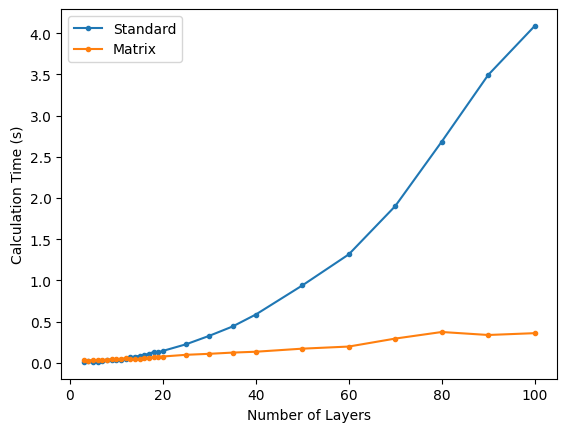

In [42]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.plot(n_layers, calc_time_std.min(1), '.-', label='Standard')
plt.plot(n_layers, calc_time_mat.min(1), '.-', label='Matrix')
plt.xlabel('Number of Layers')
plt.ylabel('Calculation Time (s)')
plt.legend()
plt.savefig('jacobian_timing_comparison.png', dpi=600)

In [17]:
rho = torch.ones(21)*40

rho[5:10] = 20.

z = torch.logspace(0, 2, len(rho))
thickness = torch.diff(z, axis=0)+1.


dbdt = fwr(rho, thickness)

In [18]:
drho = 0.02*rho
rho_pert = rho[:, None] + torch.diag(drho)
ddbdt = fwr(rho_pert, thickness)
G0 = (ddbdt - dbdt[None, :])/drho[:, None]

In [19]:
G1 = -fwr(rho, thickness, jac=True)

In [20]:
vlim = torch.abs(G1).max()

Text(0.5, 0, 'time - log10')

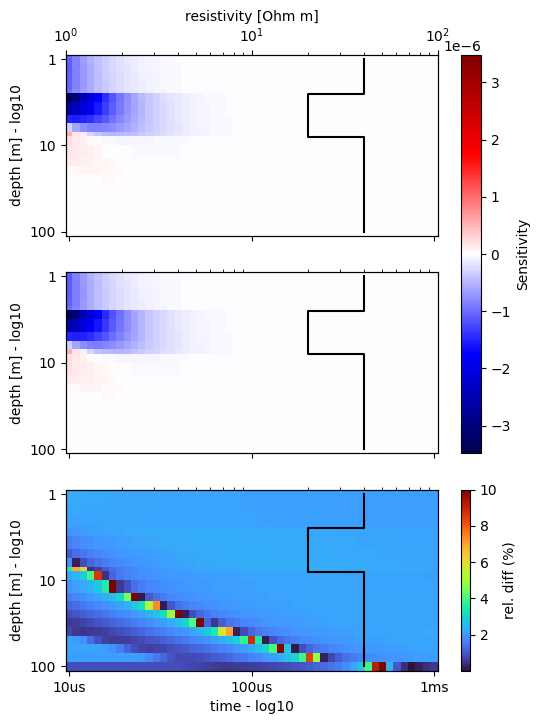

In [37]:
import matplotlib.pyplot as plt
import numpy as np

fig,axs = plt.subplots(3,1, sharex=True, sharey=True, figsize=(6,8))

pcm=axs[0].pcolor(fwr.times.log10(), z.log10(), G0, vmin=-vlim, vmax=vlim, cmap='seismic')
pcm=axs[1].pcolor(fwr.times.log10(), z.log10(), G1, vmin=-vlim, vmax=vlim, cmap='seismic')
z[5] = z[4]
z[10] = z[9]

ax_res = axs[1].twiny()
ax_res.plot(rho, z.log10(), 'k-')
ax_res.set_xscale('log'); ax_res.set_xlim(1, 100)
ax_res.set_xticks([])

ax_res = axs[0].twiny()
ax_res.plot(rho, z.log10(), 'k-')
ax_res.set_xscale('log'); ax_res.set_xlim(1, 100)
ax_res.set_xlabel('resistivity [Ohm m]')

fig.colorbar(pcm, ax=axs[:2], label='Sensitivity')
pcm=axs[2].pcolor(fwr.times.log10(), z.log10(), torch.abs(100*(G0-G1)/(G0)), vmax=10, cmap='turbo')
fig.colorbar(pcm, ax=axs[2], label='rel. diff (%)')

ax_res = axs[2].twiny()
ax_res.plot(rho, z.log10(), 'k-')
ax_res.set_xscale('log'); ax_res.set_xlim(1, 100)
ax_res.set_xticks([])

for ax in axs:
    ax.set_ylabel('depth [m] - log10')

    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(['1', '10', '100'])
    ax.set_xticks([-5, -4, -3]); ax.set_xticklabels(['10us', '100us', '1ms'])

ax.set_ylim(ax.get_ylim()[::-1])
ax.set_xlabel('time - log10')

C:\Users\au646858\AppData\Local\Temp\ipykernel_31436\470281241.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  pcm=axs[0].pcolor(fwr.times.log10(), z.log10(), torch.abs(G0).log10(), vmax=np.log10(vlim), cmap='turbo')
C:\Users\au646858\AppData\Local\Temp\ipykernel_31436\470281241.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  pcm=axs[1].pcolor(fwr.times.log10(), z.log10(), torch.abs(G1).log10(), vmax=np.log10(vlim), cmap='turbo')


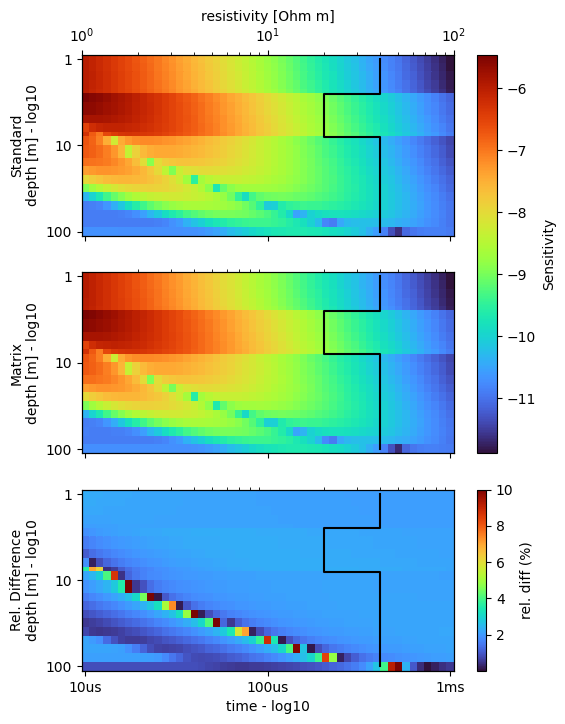

In [41]:
fig,axs = plt.subplots(3,1, sharex=True, sharey=True, figsize=(6,8))

pcm=axs[0].pcolor(fwr.times.log10(), z.log10(), torch.abs(G0).log10(), vmax=np.log10(vlim), cmap='turbo')
pcm=axs[1].pcolor(fwr.times.log10(), z.log10(), torch.abs(G1).log10(), vmax=np.log10(vlim), cmap='turbo')
z[5] = z[4]
z[10] = z[9]

ax_res = axs[1].twiny()
ax_res.plot(rho, z.log10(), 'k-')
ax_res.set_xscale('log'); ax_res.set_xlim(1, 100)
ax_res.set_xticks([])

ax_res = axs[0].twiny()
ax_res.plot(rho, z.log10(), 'k-')
ax_res.set_xscale('log'); ax_res.set_xlim(1, 100)
ax_res.set_xlabel('resistivity [Ohm m]')

fig.colorbar(pcm, ax=axs[:2], label='Sensitivity')
pcm=axs[2].pcolor(fwr.times.log10(), z.log10(), torch.abs(100*(G0-G1)/(G0)), vmax=10, cmap='turbo')
fig.colorbar(pcm, ax=axs[2], label='rel. diff (%)')

ax_res = axs[2].twiny()
ax_res.plot(rho, z.log10(), 'k-')
ax_res.set_xscale('log'); ax_res.set_xlim(1, 100)
ax_res.set_xticks([])

for ax,name in zip(axs, ['Standard', 'Matrix', 'Rel. Difference']):
    ax.set_ylabel(name+'\ndepth [m] - log10')

    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(['1', '10', '100'])
    ax.set_xticks([-5, -4, -3]); ax.set_xticklabels(['10us', '100us', '1ms'])

ax.set_ylim(ax.get_ylim()[::-1])
ax.set_xlabel('time - log10')
plt.savefig('jacobian comparison.png', dpi=600)